In [ ]:
#case study 1


<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   CustomerID        100 non-null    int64  
 1   Age               100 non-null    int64  
 2   Gender            100 non-null    str    
 3   Location          100 non-null    str    
 4   TotalPurchases    100 non-null    int64  
 5   TotalAmountSpent  100 non-null    float64
 6   LastPurchaseDate  100 non-null    str    
dtypes: float64(1), int64(3), str(3)
memory usage: 5.6 KB


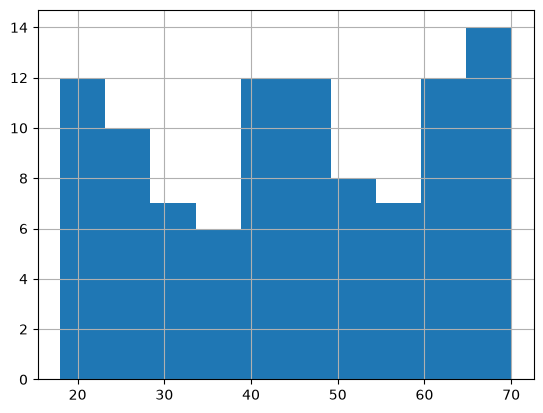

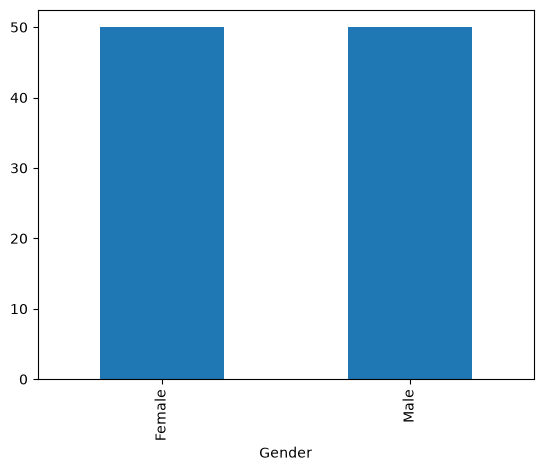

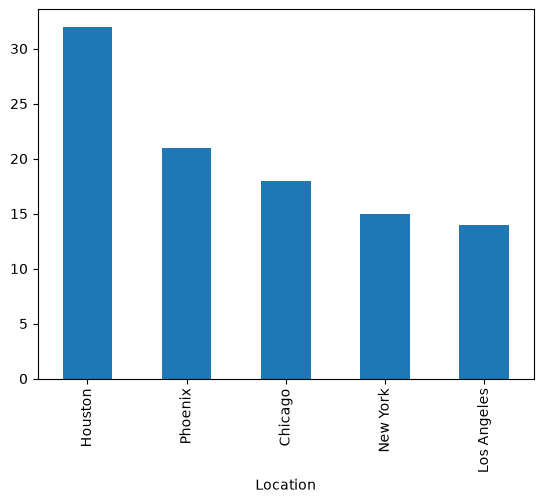

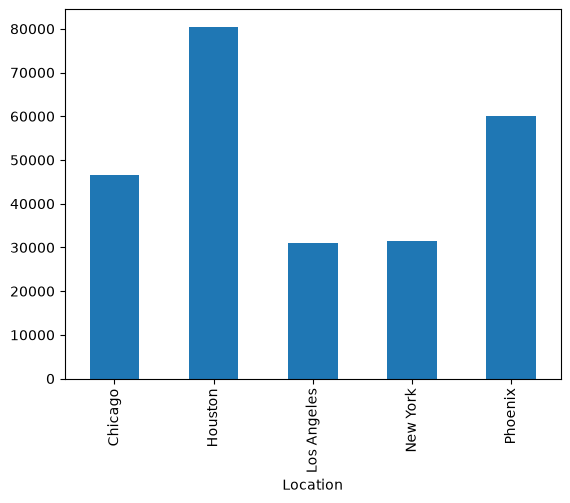

    CustomerID  Age  Gender     Location  TotalPurchases  TotalAmountSpent  \
97          98   60    Male      Houston               7           4966.48   
38          39   18  Female      Phoenix               5           4947.37   
44          45   69  Female      Houston              11           4880.54   
42          43   66  Female      Houston              15           4835.52   
40          41   20  Female      Phoenix              12           4785.73   
78          79   43    Male      Chicago              30           4766.31   
63          64   57    Male      Houston              10           4532.50   
33          34   43  Female      Chicago              28           4467.34   
87          88   49  Female      Houston               9           4380.05   
23          24   31    Male  Los Angeles               8           4302.12   

   LastPurchaseDate  
97       10-11-2024  
38       24-09-2023  
44       05-11-2023  
42       22-10-2023  
40       08-10-2023  
78       

,CustomerID,Age,Gender,Location,TotalPurchases,TotalAmountSpent,LastPurchaseDate
0,1,68,Female,Houston,24,595.11,01-01-2023
1,2,35,Male,Phoenix,29,2901.57,08-01-2023
2,3,60,Male,Phoenix,19,4109.95,15-01-2023
3,4,63,Female,Chicago,27,2324.75,22-01-2023
4,5,42,Male,Los Angeles,15,1122.67,29-01-2023
...,...,...,...,...,...,...,...
92,93,38,Female,Phoenix,17,4158.09,06-10-2024
93,94,62,Female,Houston,29,230.64,13-10-2024
96,97,22,Female,Houston,28,66.42,03-11-2024
98,99,67,Female,Houston,27,3982.74,17-11-2024


In [10]:
import numpy as numpy
import pandas as pd
import matplotlib.pyplot as plt
df=pd.read_csv("C:/Users/disha/OneDrive/Excel1/customer_data.csv")
#: Explore the Dataset
#Check the first rows.
df.head()
#Check information.
df.info()
#check datatype
df.dtypes
#check the shape
df.shape
#check columns
df.columns
#---------------------Data Cleaning
#Check Missing Values
df.isnull().sum()
#Handle missing values.
df["Age"] = df["Age"].fillna(df["Age"].median())

df["Gender"] = df["Gender"].fillna(df["Gender"].mode()[0])
#Remove Duplicate Rows
df.drop_duplicates(inplace=True)

#Standardize Location Names
df["Location"]=df["Location"].str.title()

#Descriptive Statistics
df.describe()

#Age Distribution
df["Age"].hist()
plt.show()

#Gender Distribution 

df["Gender"].value_counts()
#visualization
df["Gender"].value_counts().plot(kind="bar")
plt.show()


#Location Distribution
df["Location"].value_counts()
df["Location"].value_counts().plot(kind="bar")
plt.show()

#Average Purchase Value by Age
df.groupby("Age")["TotalAmountSpent"].mean()
df.groupby("Age")["TotalAmountSpent"].mean().plot()
plt.show

#Average Purchase Value by Gender
df.groupby("Gender")["TotalAmountSpent"].mean().plot(kind="bar")
plt.show

#Total Purchase by Location
df.groupby("Location")["TotalAmountSpent"].sum().sort_values(ascending=False)

df.groupby("Location")["TotalAmountSpent"].sum().plot(kind="bar")
plt.show()

#Most Valuable Customers
df.sort_values(by="TotalAmountSpent",ascending=False)
top_customer=df.nlargest(10,"TotalAmountSpent")
print(top_customer)

#Purchase Frequency
df.groupby("CustomerID")["TotalPurchases"].sum()
df[df["TotalPurchases"]>10]




<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   EmployeeID  100 non-null    int64  
 1   Age         100 non-null    int64  
 2   Gender      100 non-null    str    
 3   Location    100 non-null    str    
 4   JobTitle    100 non-null    str    
 5   Salary      100 non-null    float64
dtypes: float64(1), int64(2), str(3)
memory usage: 4.8 KB


C:\Users\disha\AppData\Local\Temp\ipykernel_11052\729482376.py:25: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


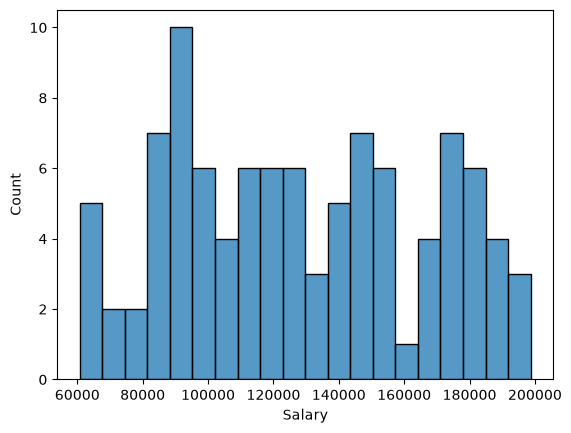

JobTitle
Project Manager      143201.954000
HR Manager           130284.838125
Software Engineer    123308.163333
Data Scientist       123259.875200
DevOps Engineer      121788.738333
Name: Salary, dtype: float64


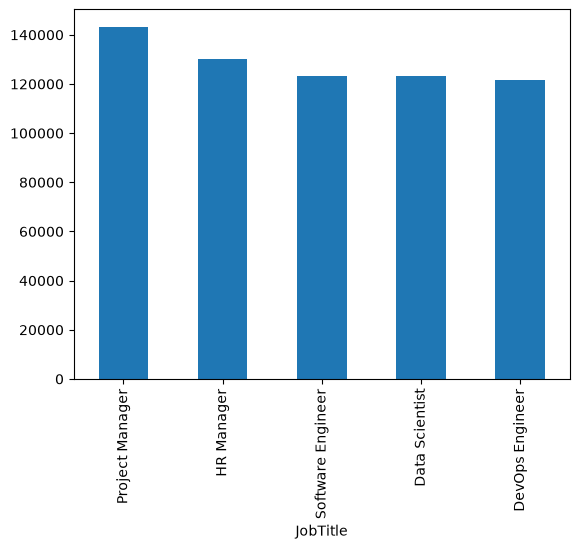

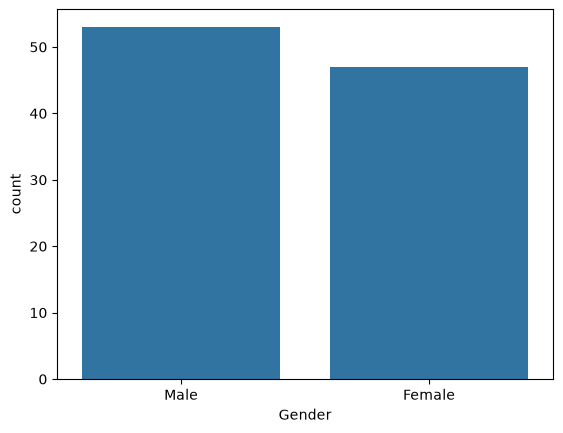

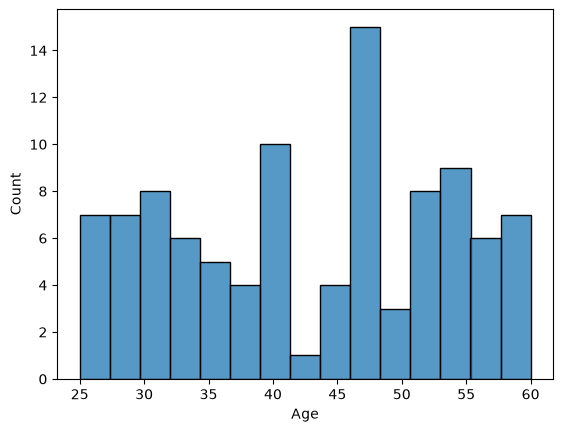

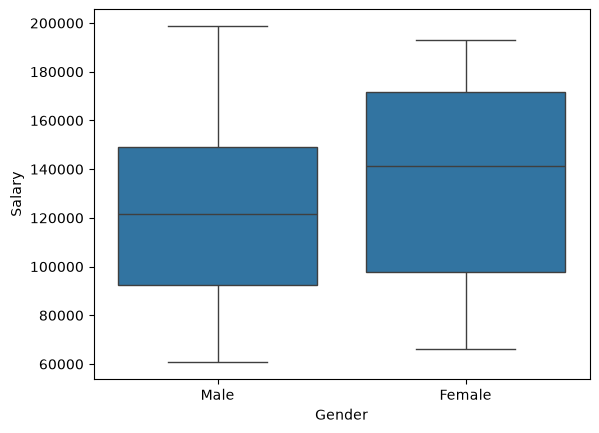

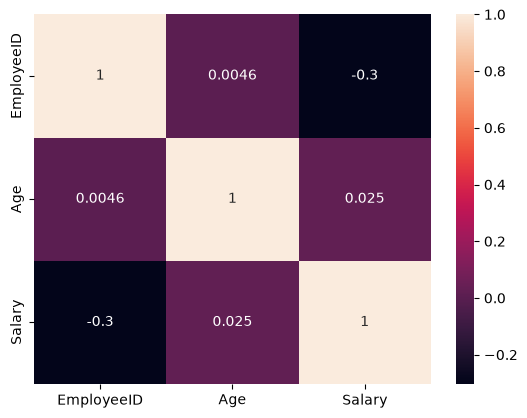

In [11]:
#CASE STUDY2
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
#Load Data
df=pd.read_csv("C:/Users/disha/OneDrive/Excel1/employees_data.csv")
#3 Data Understanding (EDA)
df.head()
df.tail()
df.sample()
#Dataset information
df.info()
#Shape
df.shape
#Columns
df.columns
#Data types
df.dtypes

#Generate a summary.
df.describe()

#Categorical summary
df.describe(include="object")


#Missing values
df.isnull().sum()

#Duplicate rows
df.duplicated().sum()

#unique values
df.nunique()

#Data Cleaning
df.drop_duplicates(inplace=True)


#Handled missing values
df["Age"]=df["Age"].fillna(df["Age"].median())

df["Gender"]=df["Gender"].fillna(df["Gender"].mode()[0])
#Fix gender values

#Convert into one format.

df["Gender"]=df["Gender"].replace({
    "M":"Male",
    "male":"Male",
    "F":"Female",
    "female":"Female"
})

#Remove impossible ages
df=df[(df["Age"]>=18) & (df["Age"]<=65)]

#Remove salary outliers (optional)
Q1=df["Salary"].quantile(0.25)
Q3=df["Salary"].quantile(0.75)

IQR=Q3-Q1

lower=Q1-1.5*IQR
upper=Q3+1.5*IQR


df=df[(df["Salary"]>=lower) & (df["Salary"]<=upper)]
#Business Analysis
#Average salary
average=df["Salary"].mean()
#Median
median=df["Salary"].median()
#Histogram
sns.histplot(df["Salary"],bins=20)
plt.show()


#Q2 Salary by Job Title
salary=df.groupby("JobTitle")["Salary"].mean().sort_values(ascending=False)
print(salary)

#visualization
salary.plot(kind="bar")
plt.show()

#Highest Paying Jobs
salary.head(10)

#Q4 Gender Distribution
df["Gender"].value_counts()
sns.countplot(data=df,x="Gender")
plt.show()

#Q5 Age Distribution
sns.histplot(df["Age"],bins=15)
plt.show()

#Q6 Average Age by Job Title
df.groupby("JobTitle")["Age"].mean()

#salary by gender
df.groupby("Gender")["Salary"].mean()
#visualization
sns.boxplot(data=df,x="Gender",y="Salary")
plt.show()

#8 Salary by Location
df.groupby("Location")["Salary"].mean().sort_values(ascending=False)

#Q9 Gender Pay Gap
pd.pivot_table(
    df,
    values="Salary",
    index="JobTitle",
    columns="Gender",
    aggfunc="mean"
)
#Correlation
df.corr(numeric_only=True)
#Heatmap
sns.heatmap(df.corr(numeric_only=True),annot=True)
plt.show()

Pracice analysis data food delivary


   OrderID CustomerID  Age  Gender    City     Restaurant    Cuisine  \
0     1001       C101   24  Female    Pune      Spice Hub     Indian   
1     1002       C102   32    Male  Mumbai    Pizza Point    Italian   
2     1003       C103   27  Female    Pune    Sushi World   Japanese   
3     1004       C104   40    Male  Nashik    Burger Town  Fast Food   
4     1005       C105   29  Female  Nagpur  Biryani House     Indian   

   OrderAmount  DeliveryTime  Rating PaymentMethod   OrderDate  
0          450            32       5           UPI  2025-01-10  
1          850            40       4          Card  2025-01-11  
2         1200            55       5           UPI  2025-01-12  
3          350            28       3          Cash  2025-01-12  
4          700            45       5          Card  2025-01-13  
705.0
Maximum order 1200
Minimum order 350
total renue 44
Average rating 4.4
Pune
City
Pune    5
Name: OrderID, dtype: int64
0    Pizza Point
Name: Restaurant, dtype: str
Pizza 

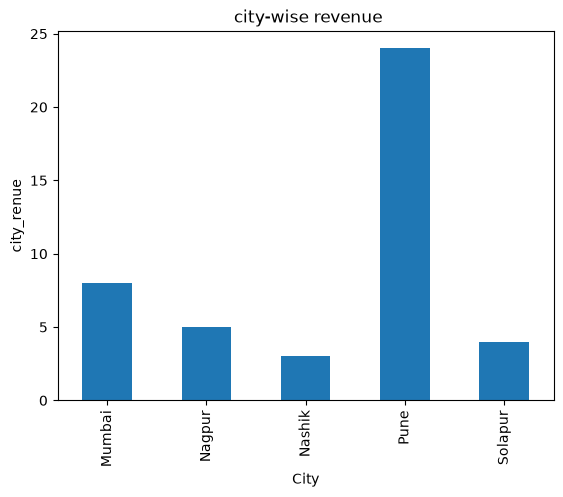

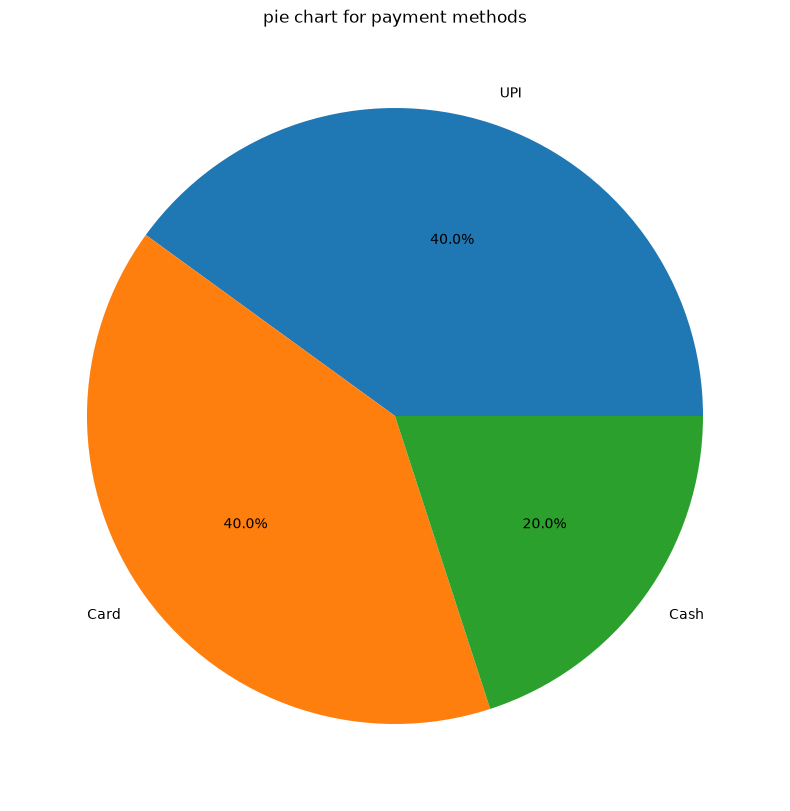

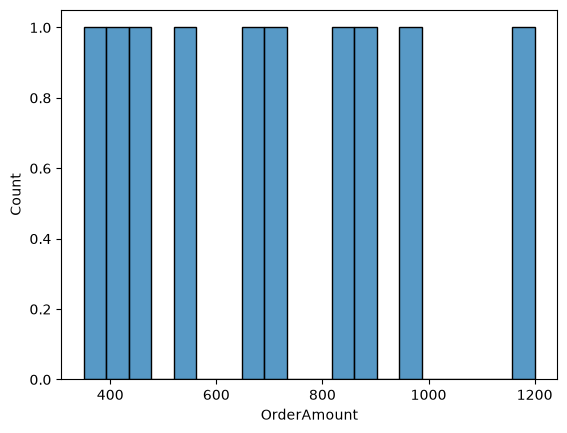

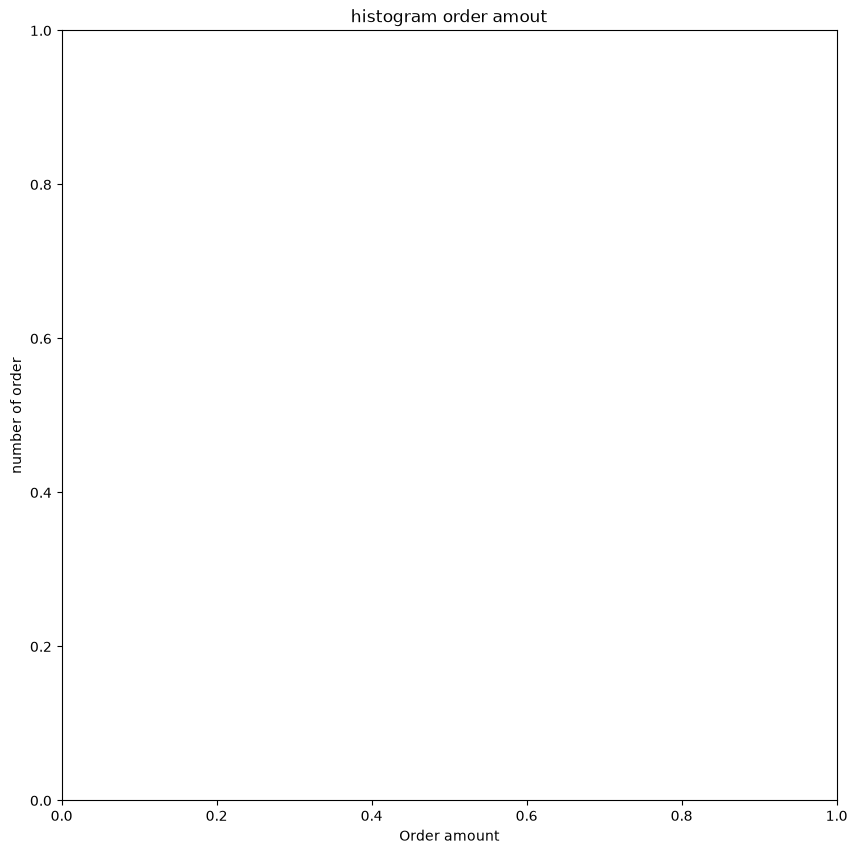

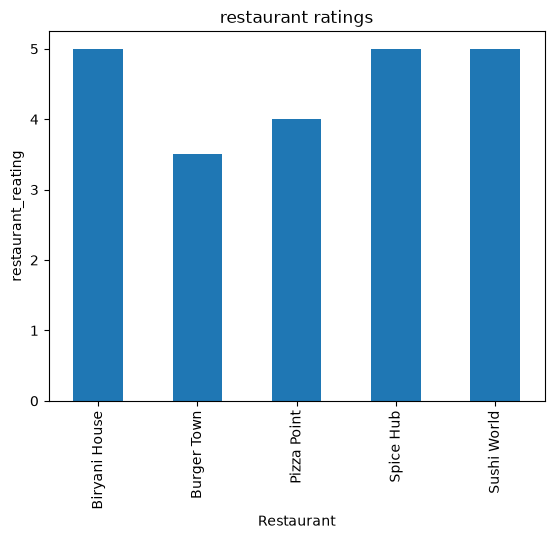

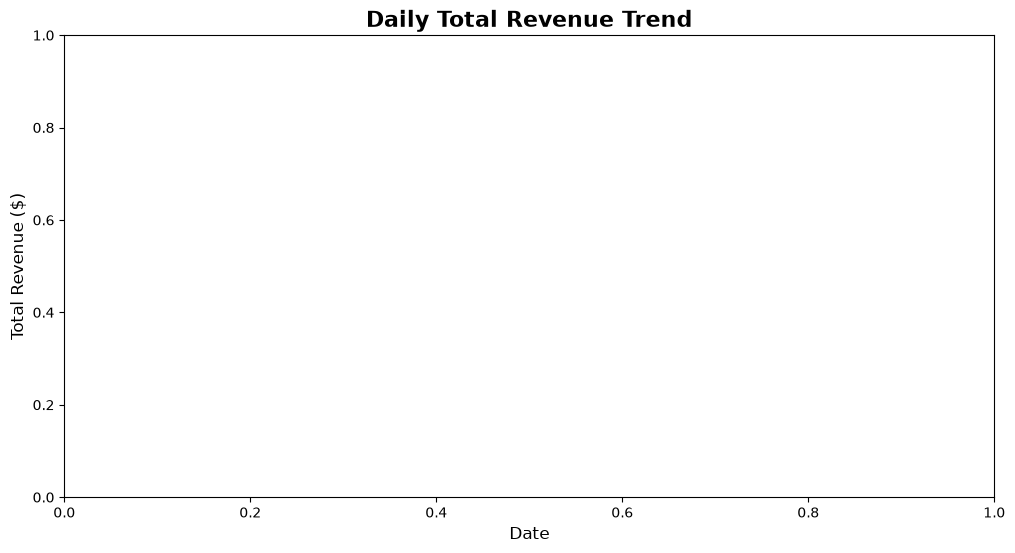

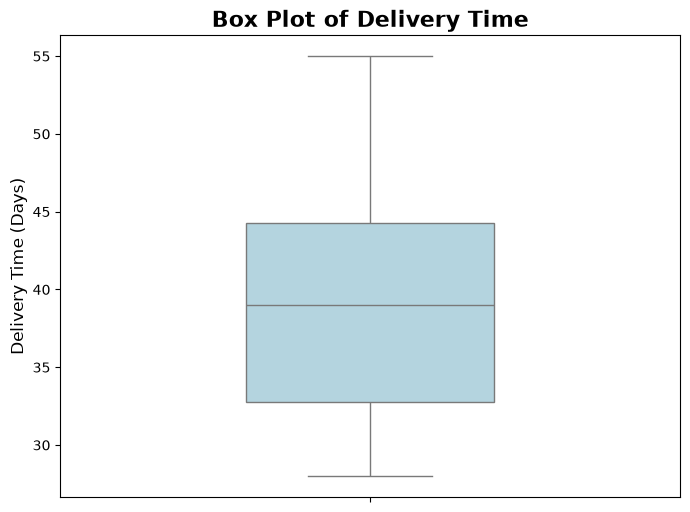

0    True
1    True
2    True
Name: totalspending, dtype: bool


Index(['OrderID', 'CustomerID', 'Age', 'Gender', 'City', 'Restaurant',
       'Cuisine', 'OrderAmount', 'DeliveryTime', 'Rating', 'PaymentMethod',
       'OrderDate'],
      dtype='str')

In [72]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#Q1Load the dataset.
df=pd.read_csv("C:/Users/disha/OneDrive/Excel1/food_delivery_dataset.csv")

#Q2 Display the first five rows.
print(df.head(5))

#Q3 Display the last five rows.
df.tail(5)

#Q4How many rows and columns are there?
df.shape

#Q5 Display all column names
df.columns

#Q6 Check the data types.
df.dtypes

#Q7 Display summary statistics.
df.describe()

#Q8 Check for missing values.
df.isnull().sum()

#Q9 Check duplicate rows.
df.duplicated().sum()

#Q10How many unique customers are there?
df.nunique()

#Q11Find the average order amount.
avg_order_amount=df["OrderAmount"].mean()
print(avg_order_amount)

#Q12 Find the maximum order amount.
print("Maximum order",df["OrderAmount"].max())

#Q13 Find the minimum order amount.
print("Minimum order",df["OrderAmount"].min())


#Q14Calculate the total revenue.
print("total renue",df["Rating"].sum())

#Q15 Find the average customer rating.
print("Average rating",df["Rating"].mean())

#Q16 Count the number of orders in each city.

df["City"].value_counts()
df.groupby("City")["OrderID"].count()

#Q17Count the number of orders by gender
df["Gender"].value_counts()

#Q18Count the number of orders by payment method.

df["PaymentMethod"].value_counts()

#Q19Which city has the highest number of orders?
print(df["City"].value_counts().idxmax())
print(df.groupby("City")["OrderID"].count().sort_values(ascending=False).head(1))


#Q20Which restaurant received the most orders?
print(df["Restaurant"].mode(0))
print(df["Restaurant"].value_counts().idxmax())


#Q21 Calculate the average order amount for each city.
df.groupby("City")["OrderAmount"].mean()

#Q22 Calculate the total revenue generated by each city.
df.groupby("City")["Rating"].sum()

#Q23Find the average rating for each restaurant.
df.groupby("Restaurant")["Rating"].mean()

#24 Find the total revenue generated by each restaurant.
df.groupby("Restaurant")["Rating"].sum()

#Q25 Calculate the average delivery time by city.
df.groupby("City")["DeliveryTime"].mean()

#Q26 Find the average order amount by gender.
df.groupby("Gender")["OrderAmount"].mean()

#Q27 Find the average order amount by payment method.
df.groupby("PaymentMethod")["OrderAmount"].mean()

#Q28Find the highest-paying customer.
df.groupby("CustomerID")["OrderAmount"].sum().idxmax()

#Q29 Calculate the total spending of each customer.
df.groupby("CustomerID")["OrderAmount"].sum()

#Q30 Find the customer who placed the most orders.
df.groupby("CustomerID")["OrderID"].count().idxmax()

#Q31Create a bar chart for city-wise revenue.
city_renue=df.groupby("City")["Rating"].sum()
city_renue.plot(kind="bar")
plt.title(" city-wise revenue")
plt.xlabel("City")
plt.ylabel("city_renue")
plt.show()

#Q32Create a pie chart for payment methods.
payment_count=df["PaymentMethod"].value_counts()
plt.figure(figsize=(10,10))
plt.pie(payment_count,
        labels=payment_count.index,
        autopct='%1.1f%%')
plt.title("pie chart for payment methods")
plt.show()

#Q33Create a histogram of order amounts.
sns.histplot(df["OrderAmount"],bins=20)
plt.figure(figsize=(10,10))
plt.title("histogram order amout")
plt.xlabel("Order amount")
plt.ylabel("number of order")
plt.show()

#Q34Create a bar chart showing restaurant ratings.
restaurant_reating=df.groupby("Restaurant")["Rating"].mean()
restaurant_reating.plot(kind="bar")
plt.title("restaurant ratings")
plt.xlabel("Restaurant")
plt.ylabel("restaurant_reating")
plt.show()


#Q35Create a line chart of daily revenue.
df["OrderDate"]=pd.to_datetime(df["OrderDate"])
daily_renue=df.groupby("OrderDate")["OrderAmount"].sum()
plt.figure(figsize=(12,6))
plt.title("Daily Total Revenue Trend", fontsize=16, fontweight='bold')
plt.xlabel("Date", fontsize=12)
plt.ylabel("Total Revenue ($)", fontsize=12)
plt.show()

#Q36Create a box plot for delivery time.
plt.figure(figsize=(8,6))
sns.boxplot(y=df["DeliveryTime"],color="lightblue",width=0.4)
plt.title("Box Plot of Delivery Time", fontsize=16, fontweight='bold')
plt.ylabel("Delivery Time (Days)", fontsize=12)
plt.show()

#Q37Which city should receive more marketing investment?
#ans=pune

#Which restaurant performs the best?===Biryani house,
#Which payment method is the most popular?=card,upi


customer_spending = df.groupby("CustomerID")["OrderAmount"].sum().sort_values(ascending=False).head(3).reset_index(name="totalspending")
print(customer_spending["totalspending"]>1000)

df.groupby("City")["OrderAmount"].sum().sort_values(ascending=False).head(2)
df.columns